# بخش اول — معرفی داده، کیفیت و تصمیم‌های آماده‌سازی

این دفترچه مدل آموزش نمی‌دهد و به API وصل نمی‌شود. کارش این است که قبل از جستجو، پاسخ‌گویی روی نظرات و پیش‌بینی `recommendation_status` معلوم شود دادهٔ خام چه شکلی است، کدام مقدار واقعاً گم‌شده است، و کدام پاک‌سازی بدون دلیل ممنوع است.

داده نسخهٔ ثابت مجموعهٔ [Digikala comments & products](https://huggingface.co/datasets/RadeAI/Digikala_comments_products/tree/89c3133b169c8d3793db88e34f56f32fee33d9db0) است: `digikala-products.csv` و `digikala-comments.csv`. هر دو با SHA-256 مرجع در `src/data_pipeline.py` یکی شده‌اند. پایگاه SQLite محلی است و داخل گیت نیست؛ اعداد زیر از JSONهای `checkpoints_full/` خوانده می‌شوند.


## چه چیزی این‌جا ثابت شده است

- بارگذاری جریانی با پارسر سخت‌گیر CSV: مقدار خام دست نمی‌خورد و فقط در ستون TEXT ذخیره می‌شود.
- خطای تعداد ستون در نظرات و محصولات: صفر.
- تکرار شناسه، تکرار متن، برچسب رسمی و اتصال محصول–نظر جدا شمرده شده‌اند.
- تصمیم‌ها در `DECISIONS.md` است. این دفترچه همان اعداد را نشان می‌دهد و قاعده‌ای را که برای بخش‌های بعد لازم است صریح می‌کند.


In [1]:
from pathlib import Path
import json
import os

import io
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib import font_manager

ROOT = Path.cwd()
if not (ROOT / "checkpoints_full" / "ingest_comments.json").exists():
    ROOT = ROOT.parent
CK = ROOT / "checkpoints_full"
assert (CK / "ingest_comments.json").exists(), CK

def load(name):
    with open(CK / name, encoding="utf-8") as f:
        return json.load(f)

ingest_c = load("ingest_comments.json")
ingest_p = load("ingest_products.json")
profile_c = load("profile_comments.json")
profile_p = load("profile_products.json")
rel_c = load("relations.json")
rel_p = load("relations_products.json")
rel_j = load("relations_join.json")
inputs = load("inputs.json")

for candidate in (
    "/System/Library/Fonts/Supplemental/Tahoma.ttf",
    "/System/Library/Fonts/Supplemental/Arial Unicode.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
):
    if os.path.exists(candidate):
        font_manager.fontManager.addfont(candidate)
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=candidate).get_name()
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

def show_fig(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buf.getvalue()))

def show_bar(labels, values, title, xlabel, color="#2c6e8a"):
    fig, ax = plt.subplots(figsize=(8.2, 3.6))
    ax.barh(list(labels)[::-1], list(values)[::-1], color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    fig.tight_layout()
    show_fig(fig)

print("checkpoints: checkpoints_full")
print("comments rows", ingest_c["rows_loaded"], "| products rows", ingest_p["rows_loaded"])


checkpoints: checkpoints_full
comments rows 6156289 | products rows 1283496


## فرهنگ داده

ستون‌ها همان سرستون فایل خام‌اند. هیچ ستونی در بارگذاری حذف یا پر نشده است.

| فایل | ستون | نقش | نکتهٔ کیفی که پایین ثابت می‌شود |
|---|---|---|---|
| products | `id` | شناسهٔ محصول | رقم خالص؛ تکرار زیاد دارد |
| products | `title_fa` | عنوان فارسی | خالی نیست؛ فاصلهٔ اضافه و گاهی خط جدید دارد |
| products | `Rate`, `Rate_cnt` | امتیاز و تعداد امتیاز ثبت‌شده برای محصول | مقیاس ۰ تا ۱۰۰، نه ۰ تا ۵ نظر |
| products | `Category1`, `Category2`, `sub_category` | دسته‌بندی | `Category2` برای بخشی از ردیف‌ها رشتهٔ خالی است |
| products | `Brand`, `Seller` | برند و فروشنده | «متفرقه» پرتکرارترین برند است و مقدار گم‌شده نیست |
| products | `Price`, `min_price_last_month` | قیمت و کمینهٔ ماه قبل | صفر در کمینهٔ ماه قبل تقریباً همه‌جا به معنی «سابقه نیست» |
| products | `Is_Fake` | پرچم غیراصل | فقط `True` / `False` |
| comments | `id`, `product_id` | شناسهٔ نظر و محصول | هر نظر به یک محصول موجود وصل است |
| comments | `title`, `body` | عنوان و متن | `nan` در عنوان بسیار شایع است؛ بدنه تقریباً همیشه متن دارد |
| comments | `created_at` | زمان ثبت، شمسی | همهٔ ردیف‌ها تقویم معتبر دارند و فایل زمانی مرتب نیست |
| comments | `rate` | امتیاز کاربر | عمدتاً ۰ تا ۵؛ یک مقدار ۲۵۰۰ خارج از مقیاس |
| comments | `recommendation_status` | برچسب رسمی سه‌حالته به‌علاوهٔ `nan` | `nan` کلاس چهارم نیست |
| comments | `is_buyer` | خریدار بودن | هر غیرخریدار برچسب پیشنهاد ندارد |
| comments | `advantages`, `disadvantages` | نکات مثبت و منفی | بیشتر `nan`؛ بقیه لیست رشته، چند صد مورد دیکشنری با کلید عددی |
| comments | `likes`, `dislikes` | رأی دیگران | عدد صحیح نامنفی |
| comments | `seller_title`, `seller_code` | فروشنده در زمان ثبت نظر | گم‌شدگی‌شان با غیرخریدار هم‌اندازه است |
| comments | `true_to_size_rate` | تناسب اندازه | تقریباً همیشه `nan`؛ پنج مقدار دسته‌ای دارد |


## یکپارچگی فایل

پارسر `csv` در حالت strict است. ردیفی که تعداد ستونش با سرستون نخواند به `parse_errors` می‌رود و وارد جدول اصلی نمی‌شود. در هر دو فایل این اتفاق نیفتاده است. وجود خط جدید داخل فیلد (متن چندخطی) خطا نیست؛ شمرده شده تا معلوم شود چرا خواندن خط‌به‌خط خام خطرناک است.


In [2]:
def integrity(name, blob, meta):
    assert blob["rows_parse_error"] == 0
    assert blob["rows_loaded"] == blob["rows_data"] == meta["rows_loaded"]
    assert blob["header_ok"] and blob["bom_utf8"]
    assert meta["matches_reference"]
    print(
        f"{name}: {blob['rows_loaded']:,} rows | {blob['file_bytes']/2**20:,.0f} MiB | "
        f"parse errors {blob['rows_parse_error']} | newline-in-field {blob['rows_with_newline_in_field']:,} | "
        f"ingest {blob['seconds']}s | rss {blob['peak_rss_mb']} MB"
    )
    print("  sha256", meta["sha256"])

integrity("comments", ingest_c, inputs["comments"])
integrity("products", ingest_p, inputs["products"])
print("comment id non-digit:", profile_c["id_invalid_non_digit"],
      "| product_id non-digit:", profile_c["product_id_invalid_non_digit"],
      "| product id non-digit:", profile_p["id_invalid_non_digit"])


comments: 6,156,289 rows | 1,219 MiB | parse errors 0 | newline-in-field 567,128 | ingest 115.1s | rss 306.7 MB
  sha256 c7a8aa3020334fde8ec24944576a03fe5785e6fe12cd01042f5836632ddf8297
products: 1,283,496 rows | 247 MiB | parse errors 0 | newline-in-field 1,146 | ingest 14.0s | rss 301.4 MB
  sha256 0f646e1b0ba5a07510a168d98ae397ae25a947b1423ccdaefc029170b7831acd
comment id non-digit: 0 | product_id non-digit: 0 | product id non-digit: 0


## گم‌شدگی، جدا از «رشتهٔ خالی»

`nan` داخل CSV رشته است، نه مقدار تهیِ پارسر. قاعدهٔ متن: رشتهٔ خالی، فاصلهٔ خالص، و هر املای `nan` (از جمله `' nan '` و `NaN`) یعنی متن نداریم. `none` و `-` در این قاعده متن خالی حساب نمی‌شوند و جدا شمرده می‌شوند. روی نظرات واقعی فقط شکل `nan` دیده شد.

برای محصولات، صفر در `Rate` وقتی `Rate_cnt` هم صفر است «بدون امتیاز» است، نه نمرهٔ صفر. صفر در `min_price_last_month` هم سابقهٔ قیمت نیست: حدود ۹۴٪ ردیف‌ها این صفر را دارند.


column                        missing       %   other sentinel     padded    newline
title                       2,866,415   46.6%              255    328,011        139
body                              637    0.0%                0    895,104    567,096
recommendation_status         894,426   14.5%                0          0          0
advantages                  5,448,084   88.5%                0          0          0
disadvantages               5,744,017   93.3%                0          0          0
seller_title                  302,181    4.9%                0    169,434          0
seller_code                   302,181    4.9%                0          0          0
true_to_size_rate           6,065,516   98.5%                0          0          0


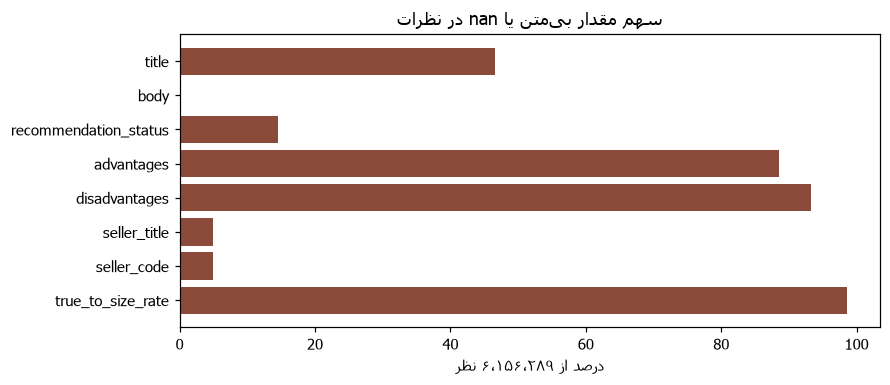

blank-text rule: empty, whitespace-only, 'nan' in any case/padding
title/body/adv/dis blank-or-nan: {'title': 2866415, 'body': 637, 'adv': 5448084, 'dis': 5744017}
products title blank-or-nan: 0
products title padded: 77809 | newline: 1146
Category2 empty string: 210108


In [3]:
n = ingest_c["rows_loaded"]
rows = []
for col in ("title", "body", "recommendation_status", "advantages", "disadvantages",
            "seller_title", "seller_code", "true_to_size_rate"):
    c = ingest_c["columns"][col]
    missing = c["empty_string"] + c["whitespace_only"] + c["literal_nan"] + c["nan_variant"]
    rows.append((col, missing, 100 * missing / n, c["other_sentinel"], c["padded_with_whitespace"], c["with_newline"]))

print(f"{'column':<24} {'missing':>12} {'%':>7} {'other sentinel':>16} {'padded':>10} {'newline':>10}")
for col, missing, pct, sent, pad, nl in rows:
    print(f"{col:<24} {missing:12,} {pct:6.1f}% {sent:16,} {pad:10,} {nl:10,}")

labels = [r[0] for r in rows]
show_bar(labels, [r[2] for r in rows], "سهم مقدار بی‌متن یا nan در نظرات", "درصد از ۶٬۱۵۶٬۲۸۹ نظر", "#8c4a3a")

blank = profile_c["blank_or_nan_text"]
print("blank-text rule:", profile_c["blank_text_rule"])
print("title/body/adv/dis blank-or-nan:", {k: blank[k] for k in ("title", "body", "adv", "dis")})
print("products title blank-or-nan:", profile_p["title_blank_or_nan"])
print("products title padded:", ingest_p["columns"]["title_fa"]["padded_with_whitespace"],
      "| newline:", ingest_p["columns"]["title_fa"]["with_newline"])
print("Category2 empty string:", dict(profile_p["value_counts"]["Category2"]["top"]).get(""))


## برچسب پیشنهاد خرید و امتیاز نظر

سه برچسب رسمی تکلیف `recommended`، `not_recommended` و `no_idea` است. مقدار چهارم در فایل `nan` است: ۸۹۴٬۴۲۶ نظر، حدود ۱۴٫۵٪. این را نباید به `no_idea` چسباند.

همهٔ ۳۰۲٬۱۸۱ نظرِ غیرخریدار همین `nan` را دارند. فروشندهٔ گم‌شده هم دقیقاً همین تعداد است. پس گم‌شدن برچسب برای غیرخریدار ساختاری است، نه نویز تصادفی. علاوه بر آن ۵۹۲٬۲۴۵ خریدار هم برچسب ندارند.

امتیاز نظر از امتیاز محصول جداست. `rate` نظر حول ۰ تا ۵ است (میانه ۴). یک ردیف `2500` دارد و خارج از بازه است؛ وارد میانگین آموزش نمی‌شود. ۵۲۹٬۰۹۸ مقدار صفر هم هست، از جمله ۴۲۵٬۷۴۵ نظر که هم‌زمان `recommended` و امتیاز ۰ دارند. صفر اینجا «نمره ندادن» محتمل‌تر از «نارضایتی کامل» است و نباید با امتیاز ۱ یکی گرفته شود.


recommendation_status: {'recommended': 4162839, 'no_idea': 594121, 'not_recommended': 504903, 'nan': 894426}
is_buyer: {'True': 5854108, 'False': 302181}
status × buyer: {'not_recommended|True': 504903, 'recommended|True': 4162839, 'nan|True': 592245, 'no_idea|True': 594121, 'nan|False': 302181}
rate min/median/max: 0.0 / 4.0 / 2500.0
zeros 529,098 | non-integer 228,128 | outside 0..5: 1 [{'row_no': 4369261, 'id': '38631814', 'product_id': '5095301', 'rate': '2500.0', 'status': 'recommended'}]


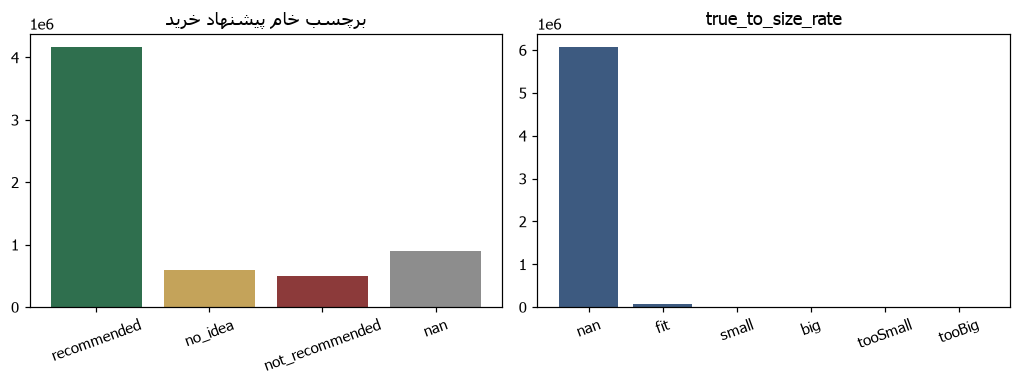

status                   rate=0    0<rate<=5   rate>5
recommended             425,745    3,737,093        1
no_idea                  20,570      573,551        0
not_recommended          57,424      447,479        0
nan                      25,359      869,067        0


In [4]:
status = profile_c["counters"]["status"]["full"]
buyer = profile_c["counters"]["is_buyer"]["full"]
cross = profile_c["counters"]["status_x_buyer"]["full"]
order = ["recommended", "no_idea", "not_recommended", "nan"]
print("recommendation_status:", {k: status[k] for k in order})
print("is_buyer:", buyer)
print("status × buyer:", cross)
assert set(cross) == {
    "recommended|True", "not_recommended|True", "no_idea|True", "nan|True", "nan|False"
}
assert cross["nan|False"] == buyer["False"] == ingest_c["columns"]["seller_title"]["literal_nan"]

rate = profile_c["numeric"]["rate"]
print(f"rate min/median/max: {rate['min']} / {rate['quantiles']['0.5']} / {rate['max']}")
print("zeros", f"{rate['zeros']:,}", "| non-integer", f"{rate['non_integer']:,}",
      "| outside 0..5:", profile_c["rate_out_of_0_5_range_count"], profile_c["rate_out_of_0_5_range"])

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
axes[0].bar(order, [status[k] for k in order], color=["#2f6f4e", "#c4a35a", "#8c3a3a", "#8d8d8d"])
axes[0].set_title("برچسب خام پیشنهاد خرید")
axes[0].tick_params(axis="x", rotation=20)
tts = profile_c["counters"]["true_to_size_rate"]["full"]
axes[1].bar(list(tts), list(tts.values()), color="#3d5a80")
axes[1].set_title("true_to_size_rate")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
show_fig(fig)

sx = profile_c["counters"]["status_x_rate"]["full"]
buckets = ("0", "(0,5]", ">5")
table = {st: {b: 0 for b in buckets} for st in order}
for key, count in sx.items():
    st, raw = key.split("|", 1)
    value = float(raw)
    bucket = "0" if value == 0 else ">5" if value > 5 else "(0,5]"
    table[st][bucket] += count
print(f"{'status':<18} {'rate=0':>12} {'0<rate<=5':>12} {'rate>5':>8}")
for st in order:
    print(f"{st:<18} {table[st]['0']:12,} {table[st]['(0,5]']:12,} {table[st]['>5']:8,}")


## تاریخ نظر

`created_at` شمسی است، مثل `23 شهریور 1402`. هر ۶٬۱۵۶٬۲۸۹ مقدار وضعیت `ok` دارد؛ روز نامعتبر دیده نشد. بازه از ۲۳ تیر ۱۳۹۵ تا ۲۶ مهر ۱۴۰۲ است. ترتیب فایل زمانی نیست: نزدیک ۵ میلیون بار ردیف بعدی از ردیف قبلی قدیمی‌تر است. هر تقسیم زمانی داده باید بعد از تبدیل به تاریخ انجام شود، نه با تکیه بر ترتیب CSV.

تبدیل به میلادی فقط برای تاریخ `ok` انجام می‌شود. چهار نقطهٔ اول فایل با تابع جلالی همین خط لوله خوانده شده‌اند و فقط برای کنترل‌اند، نه برای نمایش به کاربر.


date status: {'ok': 6156289}
shapes: {'99 M 9999': 4442344, '9 M 9999': 1713945}
min key 13950423 max key 14020726 | descents in file order 4,962,569
first parsed [jalali, gregorian]:
  ['23 شهریور 1402', [2023, 9, 14]]
  ['16 تیر 1399', [2020, 7, 6]]
  ['26 مرداد 1401', [2022, 8, 17]]
  ['28 اسفند 1399', [2021, 3, 18]]
  ['12 شهریور 1402', [2023, 9, 3]]


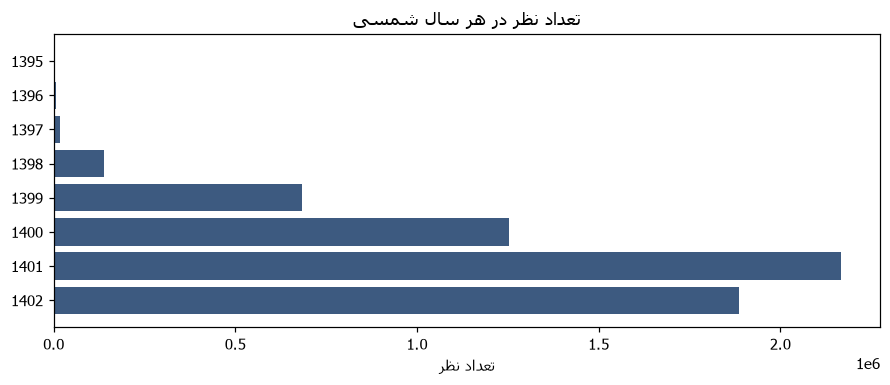

In [5]:
years = profile_c["counters"]["year"]["full"]
dates = profile_c["dates"]
print("date status:", profile_c["counters"]["date_status"]["full"])
print("shapes:", profile_c["counters"]["date_shape"]["full"])
print("min key", dates["min_key"], "max key", dates["max_key"],
      "| descents in file order", f"{dates['descents_in_file_order']:,}")
print("first parsed [jalali, gregorian]:")
for row in dates["first_parsed"]:
    print(" ", row)
ys = sorted(int(y) for y in years)
show_bar([str(y) for y in ys], [years[str(y)] if str(y) in years else years[y] for y in ys],
         "تعداد نظر در هر سال شمسی", "تعداد نظر", "#3d5a80")


## متن فارسی

بدنهٔ نظر تقریباً همیشه فارسی است. عنوان اغلب `nan` است، پس عنوان را نباید به‌تنهایی سند رضایت یا شکایت گرفت. نشانه‌هایی که نرمال‌سازی بعدی باید جداگانه و با قاعدهٔ اعلام‌شده انجام دهد: ی/ک عربی، نیم‌فاصله، کشیده، اعراب، رقم فارسی و تکرار نویسه. حذف این‌ها قبل از شمردن، آمار کیفیت را پاک می‌کند.

`advantages` و `disadvantages` عمدتاً `nan` هستند. شکل لیست روی همهٔ ردیف‌ها شمرده شده. تجزیه فقط روی همهٔ ردیف‌های دیکشنری و روی یک نمونهٔ هر ۲۰ ردیفِ لیست انجام شده و در خروجی با پیشوند `dict_shaped:` / `list_sample:` مشخص است. لیست‌های نمونه‌گیری‌شده رشته‌اند. چند صد دیکشنری کلید عددی دارند (`'0'`, `'1'`, ...)؛ یعنی لیست به‌شکل دیکشنری ذخیره شده و در نرمال‌سازی باید مقدارها به همان ترتیب کلید عددی به لیست رشته تبدیل شوند، نه اینکه دور ریخته شوند.


In [6]:
def flag_line(title, flags, denom):
    keys = ("arabic_yeh_or_alef_maksura", "arabic_kaf", "zwnj", "tatweel", "diacritics",
            "fa_digits", "emoji", "html", "url", "repeat4")
    parts = [f"{k}={flags.get(k, 0):,}" for k in keys]
    scripts = {k: v for k, v in flags.items() if k.startswith("script:")}
    print(title, "non-blank", f"{denom:,}")
    print(" ", " | ".join(parts))
    print("  script", scripts)

title_nonblank = ingest_c["rows_loaded"] - profile_c["blank_or_nan_text"]["title"]
body_nonblank = ingest_c["rows_loaded"] - profile_c["blank_or_nan_text"]["body"]
flag_line("title", profile_c["text_flags_title"], title_nonblank)
flag_line("body", profile_c["text_flags_body"], body_nonblank)
print("body length quantiles (non-blank chars):", profile_c["lengths"]["body"]["quantiles_nonzero"])

for field in ("adv", "dis"):
    print(field, "shape", profile_c["counters"][field + "_shape"]["full"])
    print(" ", field, "parse", profile_c["counters"][field + "_parse"]["top"])
print("dict keys (numeric indices):", profile_c["counters"]["dict_keys"]["top"][:8])
print("example raw dicts:")
for ex in profile_c["dict_or_listofdict_examples_first12"][:4]:
    print(" ", ex["field"], ex["row_no"], ex["raw_head"][:140])
assert profile_c["list_parse_failure_examples"] == []


title non-blank 3,289,874
  arabic_yeh_or_alef_maksura=16,386 | arabic_kaf=7,452 | zwnj=24,038 | tatweel=753 | diacritics=4,266 | fa_digits=20,580 | emoji=7,093 | html=319 | url=1 | repeat4=36,576
  script {'script:fa_only': 3232746, 'script:mixed': 25354, 'script:neither': 19726, 'script:latin_only': 12048}
body non-blank 6,155,652
  arabic_yeh_or_alef_maksura=48,994 | arabic_kaf=25,363 | zwnj=193,672 | tatweel=2,256 | diacritics=43,049 | fa_digits=194,857 | emoji=46,563 | html=1,485 | url=9 | repeat4=158,869
  script {'script:fa_only': 6114682, 'script:mixed': 36728, 'script:latin_only': 3306, 'script:neither': 936}
body length quantiles (non-blank chars): {'0': 1.0, '0.001': 3.0, '0.01': 3.0, '0.05': 5.0, '0.25': 15.0, '0.5': 29.0, '0.75': 57.0, '0.95': 152.0, '0.99': 297.0, '0.999': 654.0, '1': 4000.0}
adv shape {'literal_nan': 5448084, 'list_literal_single_quote': 707907, 'dict_literal': 288, 'list_literal_double_quote': 10}
  adv parse [['list_sample:ok_list', 35261], ['dict_shap

## محصولات

۱٬۲۸۳٬۴۹۶ ردیف محصول بارگذاری شد؛ SHA-256 با مرجع یکی است. شناسهٔ نامعتبر صفر است. عنوان خالی صفر است.

`Rate` محصول از ۰ تا ۱۰۰ است و میانهٔ خامش ۰ است، چون ۷۹۹٬۱۵۱ ردیف هم `Rate` و هم `Rate_cnt` صفر دارند. این‌ها محصول بی‌امتیازند. ۲۱ ردیف امتیاز صفر با شمارندهٔ مثبت دارند و باید جدا بمانند، نه اینکه با گروه بی‌امتیاز قاطی شوند.

برند `متفرقه` روی ۷۲۳٬۵۹۰ ردیف نشسته است. این برچسبِ موجود است، نه `nan`؛ در جستجو نباید با «برند نامشخص» یکی فرض شود مگر کاربر خودش این را بخواهد. `Category2` برای ۲۱۰٬۱۰۸ ردیف رشتهٔ خالی است. `Is_Fake=True` روی ۷۷٬۴۶۳ ردیف است.

قیمت میانه ۱٬۵۶۰٬۰۰۰ است (واحد فایل، سازگار با ریال). بیشینهٔ ۸٫۵ میلیارد یک دم دراز است، نه خطای پارس: همهٔ قیمت‌ها عدد متناهی‌اند. `min_price_last_month` برای ۱٬۲۰۸٬۱۹۵ ردیف صفر است و به‌عنوان تخفیف قابل استفاده نیست.


Rate vs Rate_cnt: {'rate_nonzero_cnt_other': 484324, 'rate0_cnt0': 799151, 'rate0_cnt_positive': 21}
Price vs min_price: {'min0': 1207994, 'min>price': 7093, 'min==price': 11931, 'min<price': 56255, 'price0': 223}
Rate: min 0 | median 0 | p99 100 | max 100 | zeros 799,172 | non_finite 0
Rate_cnt: min 0 | median 0 | p99 367 | max 30438 | zeros 799,151 | non_finite 0
Price: min 0 | median 1560000 | p99 110000000 | max 8499990000 | zeros 223 | non_finite 0
min_price_last_month: min 0 | median 0 | p99 6390000 | max 7645500000 | zeros 1,208,195 | non_finite 0


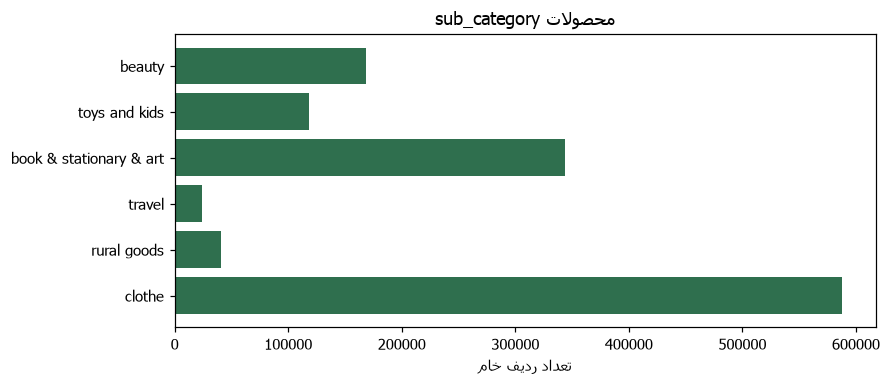

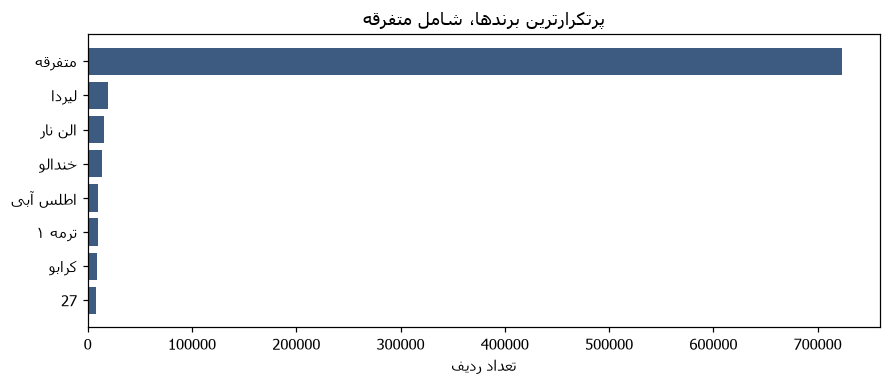

Category1 distinct 228 | Category2 602 | Brand 8961 | Seller 18585
Is_Fake {'False': 1206033, 'True': 77463}
Category2 empty 210108


In [7]:
np_ = profile_p["numeric"]
print("Rate vs Rate_cnt:", profile_p["rate_vs_rate_cnt"])
print("Price vs min_price:", profile_p["price_vs_min_price"])
for col in ("Rate", "Rate_cnt", "Price", "min_price_last_month"):
    s = np_[col]
    print(f"{col}: min {s['min']:.0f} | median {s['quantiles']['0.5']:.0f} | "
          f"p99 {s['quantiles']['0.99']:.0f} | max {s['max']:.0f} | zeros {s['zeros']:,} | non_finite {s['non_finite']}")

sub = profile_p["value_counts"]["sub_category"]["full"]
show_bar(sub.keys(), sub.values(), "sub_category محصولات", "تعداد ردیف خام", "#2f6f4e")

brand_top = profile_p["value_counts"]["Brand"]["top"][:8]
show_bar([b[0] for b in brand_top], [b[1] for b in brand_top], "پرتکرارترین برندها، شامل متفرقه", "تعداد ردیف", "#3d5a80")
print("Category1 distinct", profile_p["value_counts"]["Category1"]["distinct_exact"],
      "| Category2", profile_p["value_counts"]["Category2"]["distinct_exact"],
      "| Brand", profile_p["value_counts"]["Brand"]["distinct_exact"],
      "| Seller", profile_p["value_counts"]["Seller"]["distinct_exact"])
print("Is_Fake", profile_p["value_counts"]["Is_Fake"]["full"])
print("Category2 empty", dict(profile_p["value_counts"]["Category2"]["top"]).get(""))


## تکرار و رابطهٔ دو جدول

تکرار شناسه با هش به‌تنهایی «تکرار دقیق» اعلام نمی‌شود. گروه وقتی دقیقاً تکراری است که هش یکی باشد و هر ستون هم فقط یک مقدار متمایز داشته باشد. روی دادهٔ واقعی، گروهی که هشش یکی و محتوایش فرق کند صفر بود.

نظرات: ۳٬۲۲۶ گروه شناسهٔ تکراری؛ ۱٬۳۱۸ گروه کاملاً یکسان و ۱٬۹۰۸ گروه با محتوای متعارض. بزرگ‌ترین گروه ۳ ردیف است. ستون‌هایی که در گروه‌های متعارض بیشتر فرق می‌کنند `likes` و `dislikes` هستند، نه `product_id`. یعنی شناسهٔ تکراری معمولاً دو نسخه از همان نظر است، نه دو محصول.

متن خام (چهار فیلد عنوان، بدنه، مزیت، عیب): ۱۶۹٬۰۴۵ گروه تکراری و ۱٬۵۸۳٬۱۹۲ ردیف داخل آن‌ها. ۲۳٬۰۸۸ گروه برچسب رسمی متعارض دارند. حذف کورِ متن تکراری برچسب بخش سوم را خراب می‌کند. بزرگ‌ترین گروه متنی ۸۸٬۹۴۱ ردیف است؛ این تکرار قالبی است، نه یک کاربر.

محصولات: ۲۵۸٬۷۱۸ گروه شناسهٔ تکراری. ۲۴۶٬۹۳۳ گروه کاملاً یکسان‌اند (ردیف دوباره ذخیره‌شده). ۱۱٬۷۸۵ گروه محتوایشان فرق دارد و اختلاف تقریباً همیشه در `Price` و `Seller` است، نه در عنوان یا دسته. این گروه دوم پیشنهاد فروشنده‌های مختلف برای یک شناسه است، نه خطای عنوان.

اتصال روی فروشگاهی که هر دو جدول را با همان SHA-256 دارد: هیچ نظر یتیمی نیست. ۳۳۱٬۵۹۹ شناسهٔ متمایز محصول نظر دارند و ۶۱۶٬۷۵۳ شناسه نظر ندارند. اگر ردیف خام محصول بدون جمع‌کردن تکرار به نظر وصل شود، ۲٬۹۴۹٬۵۸۷ ردیف نظرِ اضافه ساخته می‌شود. ۲٬۰۶۳٬۵۷۳ نظر به شناسه‌ای اشاره می‌کنند که در فایل محصول تکرار شده است. جوین خام برای بازیابی و مقایسه ممنوع است.


comments duplicate ids: {'rows': 6156289, 'distinct_id': 6153060, 'duplicate_id_groups': 3226, 'groups_exact_identical_verified': 1318, 'groups_with_conflicting_content': 1908, 'groups_hash_equal_but_payload_differs': 0, 'max_group_size': 3}
 conflicting columns: {'title': 85, 'body': 241, 'created_at': 0, 'rate': 79, 'recommendation_status': 101, 'is_buyer': 22, 'product_id': 0, 'advantages': 41, 'disadvantages': 6, 'likes': 1217, 'dislikes': 294, 'seller_title': 154, 'seller_code': 147, 'true_to_size_rate': 4}
text duplicates: {'duplicate_text_groups': 169045, 'rows_in_duplicate_groups': 1583192, 'groups_with_conflicting_official_labels': 23088, 'groups_hash_equal_but_text_differs': 0, 'max_group_size': 88941, 'rows_with_no_text_at_all_strict_nan': 17}
products duplicate ids: {'rows': 1283496, 'distinct_id': 948352, 'duplicate_id_groups': 258718, 'groups_exact_identical_verified': 246933, 'groups_with_conflicting_content': 11785, 'groups_hash_equal_but_payload_differs': 0, 'max_group

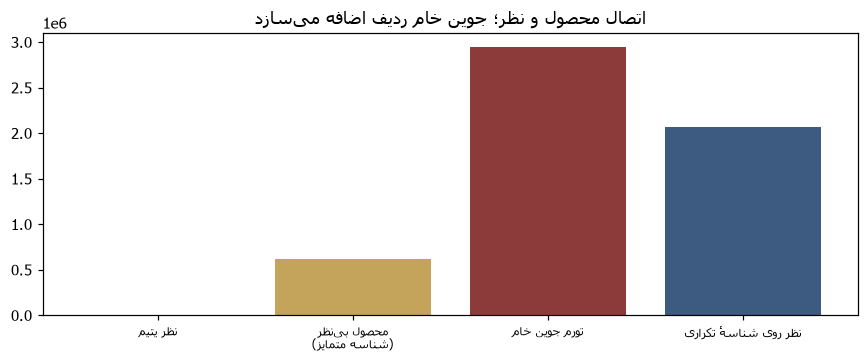

In [8]:
c = rel_c["comments"]
t = rel_c["text_duplicates_raw"]
p = rel_p["products"]
cpp = rel_c["comments_per_product"]
print("comments duplicate ids:",
      {k: c[k] for k in ("rows", "distinct_id", "duplicate_id_groups", "groups_exact_identical_verified",
                         "groups_with_conflicting_content", "groups_hash_equal_but_payload_differs", "max_group_size")})
print(" conflicting columns:", c["conflicting_groups_differing_columns"])
print("text duplicates:",
      {k: t[k] for k in ("duplicate_text_groups", "rows_in_duplicate_groups", "groups_with_conflicting_official_labels",
                         "groups_hash_equal_but_text_differs", "max_group_size", "rows_with_no_text_at_all_strict_nan")})
print("products duplicate ids:",
      {k: p[k] for k in ("rows", "distinct_id", "duplicate_id_groups", "groups_exact_identical_verified",
                         "groups_with_conflicting_content", "groups_hash_equal_but_payload_differs", "max_group_size")})
print(" product conflicts:", p["conflicting_groups_differing_columns"])
print("join:", {k: rel_j[k] for k in (
    "orphan_comment_rows", "orphan_distinct_product_ids", "distinct_products_with_comments",
    "distinct_products_without_comments", "join_inflation_if_raw_products_used",
    "comments_referencing_duplicated_product_ids")})
print("comments per product: median", cpp["quantiles"]["0.5"], "mean", round(cpp["mean"], 2),
      "max", cpp["max"], "| share top 10% products", round(cpp["share_in_top_10pct_products"], 3))

assert c["groups_hash_equal_but_payload_differs"] == 0
assert t["groups_hash_equal_but_text_differs"] == 0
assert p["groups_hash_equal_but_payload_differs"] == 0
assert rel_j["orphan_comment_rows"] == 0

labels = ["نظر یتیم", "محصول بی‌نظر\n(شناسه متمایز)", "تورم جوین خام", "نظر روی شناسهٔ تکراری"]
vals = [rel_j["orphan_comment_rows"], rel_j["distinct_products_without_comments"],
        rel_j["join_inflation_if_raw_products_used"], rel_j["comments_referencing_duplicated_product_ids"]]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(labels, vals, color=["#2f6f4e", "#c4a35a", "#8c3a3a", "#3d5a80"])
ax.set_title("اتصال محصول و نظر؛ جوین خام ردیف اضافه می‌سازد")
ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
show_fig(fig)


## تصمیم‌هایی که بخش‌های بعد حق نقض خاموش‌شان را ندارند

1. مقدار خام منبع حقیقت می‌ماند. هر نرمال‌سازی ستون جدید است و قاعده‌اش نوشته می‌شود.
2. `recommendation_status = nan` کلاس سوم نیست و با `no_idea` پر نمی‌شود. همهٔ غیرخریداران این مقدار را دارند؛ بخشی از خریداران هم همین‌طور.
3. `rate = 0` در نظر با امتیاز ۱ تا ۵ جمع نمی‌شود. تنها مقدار خارج از ۰ تا ۵، یعنی `2500`، از ویژگی عددی کنار می‌رود و در گزارش خطا می‌ماند.
4. `Rate` محصول (۰ تا ۱۰۰، و صفر به‌معنی بی‌امتیاز وقتی شمارنده صفر است) با `rate` نظر یکی گرفته نمی‌شود.
5. ردیف دقیقاً تکراری محصول حذف‌شدنی است. گروه متعارض حذف نمی‌شود: عنوان و دسته تقریباً ثابت‌اند و اختلاف در قیمت و فروشنده است. نمایندهٔ محصول برای بازیابی یکی است؛ قیمت‌ها به‌صورت چند پیشنهاد می‌مانند.
6. جوین نظر به جدول خام محصول ممنوع است. اول شناسه یکتا می‌شود. تورم این جوین ۲٬۹۴۹٬۵۸۷ ردیف است.
7. حذف متن تکراری ممنوع است تا وقتی برچسب رسمی داخل گروه یکی نشده باشد. ۲۳٬۰۸۸ گروه برچسب متعارض دارند.
8. دیکشنری مزیت/عیب با کلید عددی به لیست مقادیر تبدیل می‌شود. `true_to_size_rate` به‌خاطر پوشش خیلی کم (زیر ۲٪ مقدار غیر `nan`) ویژگی اصلی مدل برچسب نیست.
9. `min_price_last_month = 0` سابقهٔ قیمت نیست و به‌تنهایی نشانهٔ تخفیف حساب نمی‌شود.
10. برند `متفرقه` گم‌شده نیست. رشتهٔ خالی `Category2` گم‌شده است.

نزدیک‌تکرار معنایی (پارافریز) اندازه‌گیری نشده است. این دفترچه فقط برابری خام را نشان می‌دهد.


## بازتولید

مسیر فایل‌ها در کد ثابت نیست.

```bash
python3 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt
export DIGIKALA_COMMENTS_CSV=/path/to/digikala-comments.csv
export DIGIKALA_PRODUCTS_CSV=/path/to/digikala-products.csv
python src/data_pipeline.py verify
python src/data_pipeline.py run --mode full --workdir ./work
python -m unittest discover -s tests -v
```

`./work/*.sqlite` را وارد گیت نکنید. اگر فقط یکی از دو CSV را بدهید، همان جدول ساخته می‌شود و اتصال دو جدول در خروجی `orphans: null` می‌ماند. تست‌ها روی CSV مصنوعی‌اند و به فایل اصلی نیاز ندارند.

دفترچه را از ریشهٔ همین پوشه اجرا کنید تا `checkpoints_full/` پیدا شود:

```bash
jupyter nbconvert --to notebook --execute notebooks/section1_data_understanding.ipynb --inplace
```
